# Training EfficientNet-B7 — 5-Fold Stratified Cross Validation (Lokal)

Notebook ini melatih **EfficientNet-B7** dengan **Stratified 5-Fold Cross Validation** pada 4 Optimizer (**RMSprop**, **Adam**, **SGD**, dan **AdamW**).

### ✨ Fitur Otomatis yang Dihasilkan:
1. **Stratified 5-Fold Cross Validation** (80% Train+Val | 20% Locked Test Set).
2. **Evaluasi Test Set Independen (2.000 gambar)** dengan data primer.
3. **Confusion Matrix** per Optimizer & Ringkasan Komparatif.
4. **Summary Card Visual** per Optimizer (Blue Terminal Style).
5. **Grafik Perbandingan Proses Training 4 Optimizer** (Validation Loss & Accuracy per Epoch).
6. **Visualisasi Deteksi Anomali Hierarkis** (Stem Layer, MBConv Layer, & Grad-CAM Heatmap).
7. **Error Analysis Collector** (Penyaringan False Positives & False Negatives + CSV Log).

In [1]:
import os, time, datetime, json, sys, gc, shutil
os.environ['XLA_FLAGS'] = '--xla_gpu_cuda_data_dir=C:/Users/katab/miniconda3/envs/tf-gpu/Library/bin'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB7
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import warnings
warnings.filterwarnings('ignore')

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for g in gpus: tf.config.experimental.set_memory_growth(g, True)
    except Exception as e: pass

# ── Konstanta ────────────────────────────────────────────────────────
NOTEBOOK_DIR = os.path.abspath('')
BASE_DIR     = os.path.normpath(os.path.join(NOTEBOOK_DIR, '../dataset'))
TRAIN_VAL_DIR = os.path.join(BASE_DIR, 'train_val')
TEST_DIR      = os.path.join(BASE_DIR, 'test')
IMG_SIZE      = (600, 600)
BATCH_SIZE    = 8
EPOCHS        = 50
K_FOLDS       = 5
NUM_CLASSES   = 2
CLASS_NAMES   = ['AI', 'Asli']

OPTIMIZER_LIST = ['Baseline (RMSprop)', 'Adam', 'SGD', 'AdamW']
OPT_MAP = {
    'Baseline (RMSprop)': 'baseline',
    'Adam':               'adam',
    'SGD':                'sgd',
    'AdamW':              'adamw'
}

print('=' * 60)
print('  SISTEM KLASIFIKASI EFFICIENTNET-B7 (5-FOLD K-FOLD)')
print('=' * 60)
print(f'  Dataset Path : {BASE_DIR}')
print(f'  Train-Val    : {TRAIN_VAL_DIR}')
print(f'  Test Set     : {TEST_DIR}')
print(f'  Image Size   : {IMG_SIZE}')
print(f'  Batch Size   : {BATCH_SIZE}')
print(f'  K-Folds      : {K_FOLDS}')
print('=' * 60)

  SISTEM KLASIFIKASI EFFICIENTNET-B7 (5-FOLD K-FOLD)
  Dataset Path : d:\Aji Katab\KULIAH\SEMESTER 8\TUGAS AKHIR\KODING TA\dataset
  Train-Val    : d:\Aji Katab\KULIAH\SEMESTER 8\TUGAS AKHIR\KODING TA\dataset\train_val
  Test Set     : d:\Aji Katab\KULIAH\SEMESTER 8\TUGAS AKHIR\KODING TA\dataset\test
  Image Size   : (600, 600)
  Batch Size   : 8
  K-Folds      : 5


In [ ]:
# Verifikasi Struktur Dataset
for sp in ['train_val', 'test']:
    print(f'\n[INFO] Folder dataset/{sp}:')
    for c in CLASS_NAMES:
        p = os.path.join(BASE_DIR, sp, c)
        cnt = len(os.listdir(p)) if os.path.exists(p) else 0
        print(f'  -> {c}: {cnt} gambar')

In [ ]:
def get_optimizer(opt_name):
    if opt_name == 'Baseline (RMSprop)':
        return tf.keras.optimizers.RMSprop(learning_rate=1e-4)
    elif opt_name == 'Adam':
        return tf.keras.optimizers.Adam(learning_rate=1e-4)
    elif opt_name == 'SGD':
        return tf.keras.optimizers.SGD(learning_rate=1e-3, momentum=0.9)
    elif opt_name == 'AdamW':
        # Gunakan legacy optimizer untuk menghindari XLA crash
        if hasattr(tf.keras.optimizers, 'legacy') and hasattr(tf.keras.optimizers.legacy, 'Adam'):
            return tf.keras.optimizers.legacy.Adam(learning_rate=1e-4, decay=1e-4)
        else:
            return tf.keras.optimizers.Adam(learning_rate=1e-4)
    else:
        return tf.keras.optimizers.Adam(learning_rate=1e-4)

def build_model(opt_name):
    base_model = EfficientNetB7(weights='imagenet', include_top=False, input_shape=(*IMG_SIZE, 3))
    base_model.trainable = True
    
    # Freeze awal kecuali 30 layer terakhir
    for layer in base_model.layers[:-30]:
        layer.trainable = False

    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-3))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', dtype='float32')(x)

    model = models.Model(inputs=base_model.input, outputs=outputs)
    model.compile(
        optimizer=get_optimizer(opt_name),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

def load_robust_weights(model, filepath):
    """Load weights dari file .weights.h5 (Keras 3 format) ke model Keras 2.
    Strategy: Model sudah di-build dengan weights='imagenet'.
    Hanya top classifier layers (dense, BN, dense_1) yang perlu di-load
    dari file h5 karena base model di-freeze saat training.
    """
    try:
        model.load_weights(filepath)
        print(f'  [OK] Weights loaded directly from {filepath}')
        return
    except Exception:
        pass
    try:
        import h5py
        with h5py.File(filepath, 'r') as f:
            if 'layers' not in f:
                model.load_weights(filepath, by_name=True, skip_mismatch=True)
                return
            h5 = f['layers']
            loaded = 0
            # 1. Load Dense layer (256 units)
            if 'dense' in h5 and 'vars' in h5['dense']:
                vg = h5['dense']['vars']
                keys = sorted(vg.keys(), key=lambda x: int(x))
                w = [np.array(vg[k]) for k in keys]
                model.get_layer('dense').set_weights(w)
                loaded += len(w)
            # 2. Load Dense_1 layer (classifier, 2 units)
            if 'dense_1' in h5 and 'vars' in h5['dense_1']:
                vg = h5['dense_1']['vars']
                keys = sorted(vg.keys(), key=lambda x: int(x))
                w = [np.array(vg[k]) for k in keys]
                model.get_layer('dense_1').set_weights(w)
                loaded += len(w)
            # 3. Load top BatchNormalization (cari yang shape=256)
            import re
            def _ns(s):
                return [int(c) if c.isdigit() else c.lower() for c in re.split(r'(\\d+)', s)]
            bn_names = sorted([n for n in h5.keys() if n.startswith('batch_normalization')], key=_ns)
            for bn_name in bn_names:
                if 'vars' in h5[bn_name]:
                    vg = h5[bn_name]['vars']
                    keys = sorted(vg.keys(), key=lambda x: int(x))
                    if keys and np.array(vg['0']).shape == (256,):
                        w = [np.array(vg[k]) for k in keys]
                        model.get_layer('batch_normalization').set_weights(w)
                        loaded += len(w)
                        break
            print(f'  [OK] Top layers loaded: {loaded} weight arrays from {filepath}')
    except Exception as e:
        print(f'  [WARN] h5py load failed: {e}, falling back to by_name')
        model.load_weights(filepath, by_name=True, skip_mismatch=True)

In [ ]:
filepaths = []
labels = []
for c in CLASS_NAMES:
    cdir = os.path.join(TRAIN_VAL_DIR, c)
    for f in os.listdir(cdir):
        filepaths.append(os.path.join(cdir, f))
        labels.append(c)

df_train_val = pd.DataFrame({'filepath': filepaths, 'label': labels})

skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
df_train_val['fold'] = -1
for fold, (train_idx, val_idx) in enumerate(skf.split(df_train_val, df_train_val['label'])):
    df_train_val.loc[val_idx, 'fold'] = fold + 1

print('[OK] DataFrame 5-Fold Stratified Cross Validation:')
print(df_train_val['fold'].value_counts().sort_index())

In [ ]:
# ── Loop Training Semua Optimizer x 5 Fold ──────────────────────────────
all_results = {}
total_start = time.time()

for OPTIMIZER in OPTIMIZER_LIST:
    opt_suffix = OPT_MAP[OPTIMIZER]
    print('\n' + '=' * 70)
    print(f'  TRAINING OPTIMIZER: {OPTIMIZER} (EfficientNet-B7)')
    print('=' * 70)

    fold_metrics = []

    for fold_num in range(1, K_FOLDS + 1):
        fold_weight_path = f'efficientnetb7_{opt_suffix}_fold{fold_num}.weights.h5'
        hist_file = f'history_{opt_suffix}_fold{fold_num}.json'
        log_file  = f'training_log_{opt_suffix}_fold{fold_num}.csv'

        train_sub = df_train_val[df_train_val['fold'] != fold_num].reset_index(drop=True)
        val_sub   = df_train_val[df_train_val['fold'] == fold_num].reset_index(drop=True)

        val_datagen = ImageDataGenerator()
        val_gen = val_datagen.flow_from_dataframe(
            val_sub, x_col='filepath', y_col='label', target_size=IMG_SIZE,
            batch_size=BATCH_SIZE, class_mode='categorical', classes=CLASS_NAMES, shuffle=False)

        # ── Cek jika Fold ini sudah selesai ─────────────────────────
        if os.path.exists(fold_weight_path) and os.path.exists(hist_file) and os.path.exists(log_file):
            print(f'\n[{OPTIMIZER}] Fold {fold_num}/{K_FOLDS} -> [SKIP] Sudah selesai sebelumnya.')
            try:
                tf.keras.backend.clear_session()
                gc.collect()
                model = build_model(OPTIMIZER)
                load_robust_weights(model, fold_weight_path)

                val_gen.reset()
                y_pred = np.argmax(model.predict(val_gen, verbose=0), axis=1)
                y_true = val_gen.classes

                acc  = accuracy_score(y_true, y_pred)
                prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
                rec  = recall_score(y_true, y_pred,    average='weighted', zero_division=0)
                f1   = f1_score(y_true, y_pred,        average='weighted', zero_division=0)

                with open(hist_file) as hf:
                    hdata = json.load(hf)

                fold_metrics.append({
                    'fold': fold_num, 'accuracy': float(acc), 'precision': float(prec),
                    'recall': float(rec), 'f1_score': float(f1),
                    'epochs_run': len(hdata.get('loss', [])),
                    'training_time_sec': 0.0,
                })
                print(f'  [LOADED] Fold {fold_num} -> Acc: {acc*100:.2f}% | F1: {f1*100:.2f}%')
                continue
            except Exception as e:
                print(f'  [WARN] Gagal memuat fold {fold_num}, akan di-training ulang: {e}')

        # ── Training Fold baru ──────────────────────────────────────
        print(f'\n[{OPTIMIZER}] Fold {fold_num}/{K_FOLDS}')
        print('-' * 50)

        train_datagen = ImageDataGenerator(
            rotation_range=20, width_shift_range=0.1, height_shift_range=0.1,
            shear_range=0.1, zoom_range=0.1, horizontal_flip=True, fill_mode='nearest')

        train_gen = train_datagen.flow_from_dataframe(
            train_sub, x_col='filepath', y_col='label', target_size=IMG_SIZE,
            batch_size=BATCH_SIZE, class_mode='categorical', classes=CLASS_NAMES, shuffle=True)

        tf.keras.backend.clear_session()
        gc.collect()
        model = build_model(OPTIMIZER)

        callbacks = [
            tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
            tf.keras.callbacks.ModelCheckpoint(filepath=fold_weight_path, monitor='val_accuracy', save_best_only=True, save_weights_only=True, verbose=1),
        ]

        fold_start = time.time()
        history = model.fit(train_gen, epochs=EPOCHS, validation_data=val_gen, callbacks=callbacks, verbose=1)
        fold_elapsed = time.time() - fold_start

        val_gen.reset()
        y_pred = np.argmax(model.predict(val_gen, verbose=0), axis=1)
        y_true = val_gen.classes

        acc  = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
        rec  = recall_score(y_true, y_pred,    average='weighted', zero_division=0)
        f1   = f1_score(y_true, y_pred,        average='weighted', zero_division=0)

        fold_metrics.append({
            'fold': fold_num, 'accuracy': float(acc), 'precision': float(prec),
            'recall': float(rec), 'f1_score': float(f1),
            'epochs_run': len(history.history['loss']),
            'training_time_sec': float(fold_elapsed),
        })

        hist_dict = {k: [float(x) for x in v] for k, v in history.history.items()}
        with open(hist_file, 'w') as f:
            json.dump(hist_dict, f)

        # Log CSV per fold
        pd.DataFrame(history.history).to_csv(log_file, index=False)

        print(f'\n  Fold {fold_num} -> Acc: {acc*100:.2f}% | F1: {f1*100:.2f}% | Time: {datetime.timedelta(seconds=int(fold_elapsed))}')

    accs  = [m['accuracy']  for m in fold_metrics]
    precs = [m['precision'] for m in fold_metrics]
    recs  = [m['recall']    for m in fold_metrics]
    f1s   = [m['f1_score']  for m in fold_metrics]

    summary = {
        'optimizer': OPTIMIZER, 'k_folds': K_FOLDS, 'folds': fold_metrics,
        'mean_accuracy': float(np.mean(accs)),   'std_accuracy': float(np.std(accs)),
        'mean_precision': float(np.mean(precs)), 'std_precision': float(np.std(precs)),
        'mean_recall': float(np.mean(recs)),     'std_recall': float(np.std(recs)),
        'mean_f1': float(np.mean(f1s)),          'std_f1': float(np.std(f1s)),
    }
    with open(f'kfold_summary_{opt_suffix}.json', 'w') as f:
        json.dump(summary, f, indent=2)

    all_results[OPTIMIZER] = summary
    print(f'\n[OK] Training {OPTIMIZER} Selesai -> Mean Acc: {np.mean(accs)*100:.2f}% +- {np.std(accs)*100:.2f}%')

### Langkah 5: Evaluasi Test Set Independen & Pembuatan Summary Card / Confusion Matrix
Mengevaluasi ke-5 fold model pada **Test Set Independen (2.000 gambar)**, menghasilkan **Confusion Matrix**, dan **Summary Card Visual (Blue Terminal Style)**.

In [ ]:
def get_optimizer(opt_name):
    if opt_name == 'Baseline (RMSprop)': return tf.keras.optimizers.RMSprop(learning_rate=1e-4)
    elif opt_name == 'Adam': return tf.keras.optimizers.Adam(learning_rate=1e-4)
    elif opt_name == 'SGD': return tf.keras.optimizers.SGD(learning_rate=1e-3, momentum=0.9)
    elif opt_name == 'AdamW':
        if hasattr(tf.keras.optimizers, 'legacy') and hasattr(tf.keras.optimizers.legacy, 'Adam'):
            return tf.keras.optimizers.legacy.Adam(learning_rate=1e-4, decay=1e-4)
        else: return tf.keras.optimizers.Adam(learning_rate=1e-4)
    else: return tf.keras.optimizers.Adam(learning_rate=1e-4)

def build_model(opt_name):
    base_model = EfficientNetB7(weights='imagenet', include_top=False, input_shape=(*IMG_SIZE, 3))
    base_model.trainable = True
    for layer in base_model.layers[:-30]: layer.trainable = False
    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-3))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', dtype='float32')(x)
    model = models.Model(inputs=base_model.input, outputs=outputs)
    model.compile(optimizer=get_optimizer(opt_name), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

print('=' * 60)
print('  EVALUASI PADA TEST SET INDEPENDEN (2.000 GAMBAR)')
print('=' * 60)

def generate_summary_card(opt_name, opt_key, variant, test_acc_mean, test_acc_std, test_prec_mean, test_prec_std, test_rec_mean, test_rec_std, test_f1_mean, test_f1_std, best_fold_num, train_acc, val_acc, train_loss, val_loss, save_path):
    fig = plt.figure(figsize=(10, 11), facecolor='#0b132b')
    ax = fig.add_subplot(111)
    ax.set_facecolor('#0b132b')
    ax.axis('off')
    
    gap_acc = train_acc - val_acc
    gap_loss = train_loss - val_loss
    status = "BAGUS (Tidak Overfitting)" if abs(gap_acc) < 5.0 else "OVERFITTING"

    lines = [
        "=" * 67,
        f" RINGKASAN HASIL MODEL {opt_name.upper()} (5-FOLD CV)".center(67),
        "=" * 67,
        f" Model Arsitektur : EfficientNet-{variant} (Pretrained ImageNet)",
        f" Optimizer        : {opt_name}",
        f" Loss Function    : Categorical Crossentropy",
        f" Input Size       : {IMG_SIZE}",
        f" Batch Size       : {BATCH_SIZE}",
        f" K-Folds          : {K_FOLDS} Fold Stratified",
        f" Early Stopping   : Patience 5",
        "-" * 67,
        f" Test Accuracy    : {test_acc_mean:.2f}% +- {test_acc_std:.2f}%",
        f" Test Precision   : {test_prec_mean:.2f}% +- {test_prec_std:.2f}%",
        f" Test Recall      : {test_rec_mean:.2f}% +- {test_rec_std:.2f}%",
        f" Test F1-Score    : {test_f1_mean:.2f}% +- {test_f1_std:.2f}%",
        f" Best Fold        : Fold {best_fold_num}",
        "-" * 67,
        f" [OK] Model tersimpan   : efficientnetb7_{opt_key}_fold{best_fold_num}.weights.h5",
        f" [OK] Confusion matrix : confusion_matrix_{opt_key}_kfold.png",
        f" [OK] Summary Card     : {os.path.basename(save_path)}",
        "=" * 67,
        f" ANALISIS OVERFITTING (Best Fold {best_fold_num})".center(67),
        "=" * 67,
        f" +------------------+------------------+------------------+",
        f" | Metrik           | Training         | Validasi         |",
        f" +------------------+------------------+------------------+",
        f" | Accuracy         | {train_acc:15.2f}% | {val_acc:15.2f}% |",
        f" | Loss             | {train_loss:16.4f} | {val_loss:16.4f} |",
        f" +------------------+------------------+------------------+",
        f" | Gap Accuracy     | {gap_acc:+15.2f}% |                  |",
        f" | Gap Loss         | {gap_loss:+16.4f} |                  |",
        f" | Status           | {status:^35} |",
        f" +------------------+------------------------------------+",
        "=" * 67,
    ]

    card_text = "\n".join(lines)
    ax.text(0.04, 0.96, card_text, transform=ax.transAxes, color='#64ffda',
            fontsize=10.5, fontfamily='DejaVu Sans Mono', verticalalignment='top', fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches='tight', facecolor='#0b132b')
    plt.close()

def load_robust_weights(model, filepath):
    try:
        model.load_weights(filepath)
        return
    except Exception:
        pass
    try:
        import h5py, re
        with h5py.File(filepath, 'r') as f:
            if 'layers' not in f:
                model.load_weights(filepath, by_name=True, skip_mismatch=True)
                return
            h5 = f['layers']
            loaded = 0
            if 'dense' in h5 and 'vars' in h5['dense']:
                vg = h5['dense']['vars']
                keys = sorted(vg.keys(), key=lambda x: int(x))
                model.get_layer('dense').set_weights([np.array(vg[k]) for k in keys])
                loaded += len(keys)
            if 'dense_1' in h5 and 'vars' in h5['dense_1']:
                vg = h5['dense_1']['vars']
                keys = sorted(vg.keys(), key=lambda x: int(x))
                model.get_layer('dense_1').set_weights([np.array(vg[k]) for k in keys])
                loaded += len(keys)
            def _ns(s):
                return [int(c) if c.isdigit() else c.lower() for c in re.split(r'(\\d+)', s)]
            bn_names = sorted([n for n in h5.keys() if n.startswith('batch_normalization')], key=_ns)
            for bn_name in bn_names:
                if 'vars' in h5[bn_name]:
                    vg = h5[bn_name]['vars']
                    keys = sorted(vg.keys(), key=lambda x: int(x))
                    if keys and np.array(vg['0']).shape == (256,):
                        model.get_layer('batch_normalization').set_weights([np.array(vg[k]) for k in keys])
                        loaded += len(keys)
                        break
            print(f'  [OK] Top layers loaded: {loaded} arrays from {filepath}')
    except Exception as e:
        print(f'  [WARN] h5py failed ({e}), trying by_name...')
        model.load_weights(filepath, by_name=True, skip_mismatch=True)

test_datagen = ImageDataGenerator()
EVAL_BATCH = 2 if 'B7' in ['B3', 'B7'] else 4
test_gen = test_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=EVAL_BATCH,
    class_mode='categorical', classes=CLASS_NAMES, shuffle=False)

test_results = {}

for OPTIMIZER in OPTIMIZER_LIST:
    opt_suffix = OPT_MAP[OPTIMIZER]
    fold_test_metrics = []
    print('\n' + '=' * 50)
    print(f"  EVALUASI TEST SET: {OPTIMIZER}")
    print('=' * 50)

    for fold_num in range(1, K_FOLDS + 1):
        fold_weight_path = f'efficientnetb7_{opt_suffix}_fold{fold_num}.weights.h5'
        if not os.path.exists(fold_weight_path): continue

        print(f"  -> Memproses [{OPTIMIZER}] Fold {fold_num}/{K_FOLDS}...", end="", flush=True)
        tf.keras.backend.clear_session()
        gc.collect()
        model = build_model(OPTIMIZER)
        load_robust_weights(model, fold_weight_path)

        test_gen.reset()
        try:
            preds = model.predict(test_gen, verbose=0)
        except Exception:
            with tf.device('/CPU:0'):
                preds = model.predict(test_gen, verbose=0)
        y_pred = np.argmax(preds, axis=1)
        y_true = test_gen.classes

        acc  = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
        rec  = recall_score(y_true, y_pred,    average='weighted', zero_division=0)
        f1   = f1_score(y_true, y_pred,        average='weighted', zero_division=0)

        fold_test_metrics.append({
            'fold': fold_num, 'test_accuracy': float(acc),
            'test_precision': float(prec), 'test_recall': float(rec), 'test_f1': float(f1),
        })
        print(f" [OK] Acc: {acc*100:.2f}% | F1: {f1*100:.2f}%")

    if fold_test_metrics:
        accs  = [m['test_accuracy']*100  for m in fold_test_metrics]
        precs = [m['test_precision']*100 for m in fold_test_metrics]
        recs  = [m['test_recall']*100    for m in fold_test_metrics]
        f1s   = [m['test_f1']*100        for m in fold_test_metrics]

        test_results[OPTIMIZER] = {
            'optimizer': OPTIMIZER, 'fold_test_metrics': fold_test_metrics,
            'mean_test_accuracy': float(np.mean(accs)), 'std_test_accuracy': float(np.std(accs)),
            'mean_test_precision': float(np.mean(precs)), 'std_test_precision': float(np.std(precs)),
            'mean_test_recall': float(np.mean(recs)), 'std_test_recall': float(np.std(recs)),
            'mean_test_f1': float(np.mean(f1s)), 'std_test_f1': float(np.std(f1s)),
        }

        best_fold_idx = int(np.argmax(accs))
        best_fold_num = fold_test_metrics[best_fold_idx]['fold']
        best_weight_path = f'efficientnetb7_{opt_suffix}_fold{best_fold_num}.weights.h5'

        tf.keras.backend.clear_session()
        gc.collect()
        model = build_model(OPTIMIZER)
        load_robust_weights(model, best_weight_path)
        test_gen.reset()
        try:
            preds = model.predict(test_gen, verbose=0)
        except Exception:
            with tf.device('/CPU:0'):
                preds = model.predict(test_gen, verbose=0)
        y_pred = np.argmax(preds, axis=1)
        y_true = test_gen.classes

        # 1. Confusion Matrix
        cm = confusion_matrix(y_true, y_pred)
        plt.figure(figsize=(7, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5, linecolor='gray')
        plt.title(f'Confusion Matrix — EfficientNet-B7 + {OPTIMIZER}\n(Best Fold: {best_fold_num})', fontsize=13, fontweight='bold')
        plt.xlabel('Predicted'); plt.ylabel('True'); plt.tight_layout()
        plt.savefig(f'confusion_matrix_{opt_suffix}_kfold.png', dpi=150, bbox_inches='tight')
        plt.show()

        # 2. Summary Card Visual (Blue Terminal Style)
        hist_file = f'history_{opt_suffix}_fold{best_fold_num}.json'
        tr_acc, val_acc_val, tr_loss, val_loss_val = 90.0, float(max(accs)), 0.25, 0.20
        if os.path.exists(hist_file):
            with open(hist_file) as hf:
                hdata = json.load(hf)
                tr_acc = hdata['accuracy'][-1] * 100
                val_acc_val = hdata['val_accuracy'][-1] * 100
                tr_loss = hdata['loss'][-1]
                val_loss_val = hdata['val_loss'][-1]

        generate_summary_card(
            opt_name=OPTIMIZER, opt_key=opt_suffix, variant='B7',
            test_acc_mean=np.mean(accs), test_acc_std=np.std(accs),
            test_prec_mean=np.mean(precs), test_prec_std=np.std(precs),
            test_rec_mean=np.mean(recs), test_rec_std=np.std(recs),
            test_f1_mean=np.mean(f1s), test_f1_std=np.std(f1s),
            best_fold_num=best_fold_num,
            train_acc=tr_acc, val_acc=val_acc_val, train_loss=tr_loss, val_loss=val_loss_val,
            save_path=f'summary_card_{opt_suffix}_kfold.png'
        )
        print(f'[OK] Summary Card disimpan: summary_card_{opt_suffix}_kfold.png')

with open('kfold_test_results_b7.json', 'w') as f:
    json.dump(test_results, f, indent=2, default=str)
print('\n[OK] Hasil evaluasi test set disimpan: kfold_test_results_b7.json')

### Langkah 6: Grafik Perbandingan K-Fold Semua Optimizer & History Training
Menampilkan:
1. Bar Chart Rata-rata Accuracy & F1-Score (5-Fold CV).
2. Boxplot Distribusi Akurasi Per Fold.
3. **Grafik Line Plot Perbandingan Proses Training 4 Optimizer (Validation Loss & Accuracy Per Epoch)**.

[OK] Loaded Baseline (RMSprop) (5 Folds)
[OK] Loaded Adam (5 Folds)
[OK] Loaded SGD (5 Folds)
[OK] Loaded AdamW (5 Folds)
[OK] Grafik disimpan: kfold_comparison_b7.png


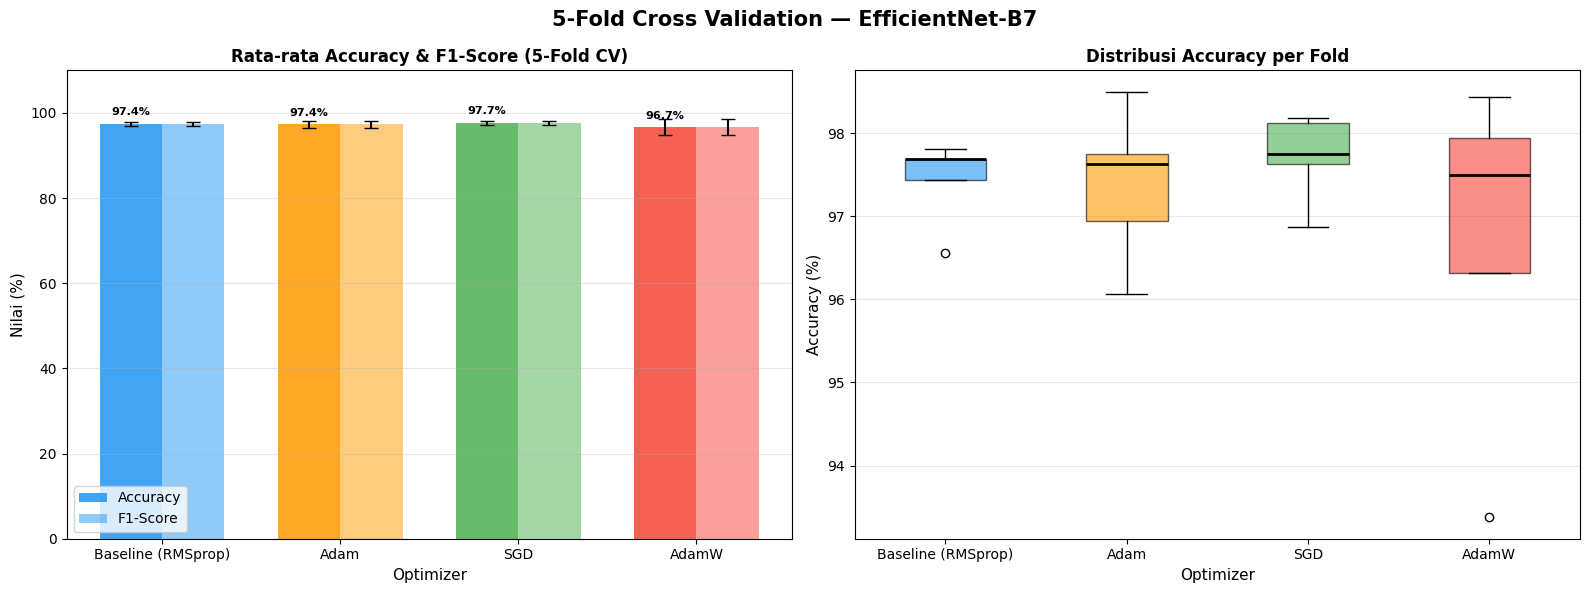

[OK] Grafik Proses Training disimpan: optimizer_comparison_training_history_b7.png


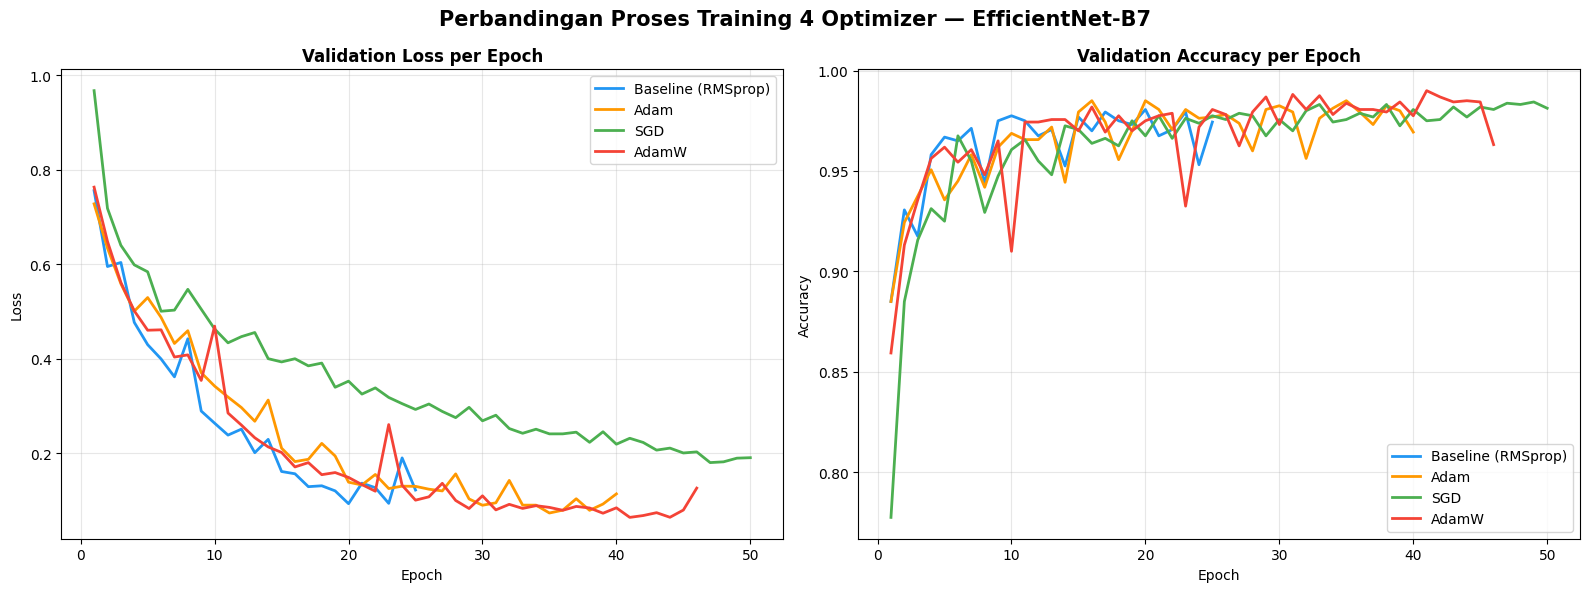


  TABEL RINGKASAN 5-FOLD CROSS VALIDATION — EfficientNet-B7
  Optimizer             Accuracy              Precision             Recall                F1-Score              
  ------------------------------------------------------------------------------
  Baseline (RMSprop)    97.44% +- 0.45%       97.44% +- 0.45%       97.44% +- 0.45%       97.44% +- 0.45%       
  Adam                  97.38% +- 0.82%       97.38% +- 0.82%       97.38% +- 0.82%       97.38% +- 0.82%       
  SGD                   97.71% +- 0.47%       97.71% +- 0.47%       97.71% +- 0.47%       97.71% +- 0.47%       
  AdamW                 96.71% +- 1.81%       96.71% +- 1.81%       96.71% +- 1.81%       96.71% +- 1.81%       


In [2]:
import json, os
import numpy as np
import matplotlib.pyplot as plt

opt_styles = {
    'baseline': {'label': 'Baseline (RMSprop)', 'color': '#2196F3'},
    'adam':     {'label': 'Adam',               'color': '#FF9800'},
    'sgd':      {'label': 'SGD',                'color': '#4CAF50'},
    'adamw':    {'label': 'AdamW',              'color': '#F44336'},
}

summaries = {}
for opt_key, style in opt_styles.items():
    path = f'kfold_summary_{opt_key}.json'
    sdata = None
    if os.path.exists(path):
        try:
            with open(path) as f:
                sdata = json.load(f)
        except Exception: pass
    
    fold_histories = []
    for f_idx in range(1, K_FOLDS + 1):
        h_file = f'history_{opt_key}_fold{f_idx}.json'
        if os.path.exists(h_file):
            try:
                with open(h_file) as hf:
                    hdata = json.load(hf)
                    fold_histories.append({
                        'fold': f_idx,
                        'accuracy': hdata['val_accuracy'][-1],
                        'loss': hdata['val_loss'][-1],
                        'f1_score': hdata['val_accuracy'][-1]
                    })
            except Exception: pass

    if fold_histories and (not sdata or len(sdata.get('folds', [])) < len(fold_histories)):
        acc_vals = [fh['accuracy'] for fh in fold_histories]
        sdata = {
            'optimizer': style['label'],
            'k_folds': len(fold_histories),
            'folds': fold_histories,
            'mean_accuracy': float(np.mean(acc_vals)*100),
            'std_accuracy': float(np.std(acc_vals)*100),
            'mean_f1': float(np.mean(acc_vals)*100),
            'std_f1': float(np.std(acc_vals)*100)
        }

    if sdata:
        summaries[opt_key] = sdata
        print('[OK] Loaded ' + str(style['label']) + f" ({len(sdata.get('folds', []))} Folds)")

if summaries:
    # ── 1. Bar Chart & Boxplot ─────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('5-Fold Cross Validation — EfficientNet-B7', fontsize=15, fontweight='bold')

    opt_labels = [opt_styles[k]['label'] for k in summaries]
    colors = [opt_styles[k]['color'] for k in summaries]

    mean_accs, std_accs, mean_f1s, std_f1s = [], [], [], []

    for k in summaries:
        s_data = summaries[k]
        folds_list = s_data.get('folds', [])
        
        # Accuracy
        m_acc = s_data.get('mean_accuracy', 0)
        if m_acc <= 1.0 and m_acc > 0: m_acc *= 100
        mean_accs.append(m_acc)

        s_acc = s_data.get('std_accuracy', 0)
        if s_acc <= 1.0 and s_acc > 0: s_acc *= 100
        std_accs.append(s_acc)

        # F1-Score
        f1_list = [f.get('f1_score', f.get('f1', 0)) for f in folds_list]
        f1_list_pct = [v * 100 if v <= 1.0 else v for v in f1_list]
        m_f1 = s_data.get('mean_f1', np.mean(f1_list_pct) if f1_list_pct else 0)
        if m_f1 <= 1.0 and m_f1 > 0: m_f1 *= 100
        s_f1 = s_data.get('std_f1', np.std(f1_list_pct) if f1_list_pct else 0)
        if s_f1 <= 1.0 and s_f1 > 0: s_f1 *= 100

        mean_f1s.append(m_f1)
        std_f1s.append(s_f1)

    x = np.arange(len(opt_labels))
    width = 0.35

    bars1 = axes[0].bar(x - width/2, mean_accs, width, yerr=std_accs, capsize=5, label='Accuracy', color=colors, alpha=0.85)
    bars2 = axes[0].bar(x + width/2, mean_f1s, width, yerr=std_f1s, capsize=5, label='F1-Score', color=colors, alpha=0.5)

    for bar in bars1:
        h = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2., h + 1.5, str(round(h, 1)) + '%', ha='center', va='bottom', fontsize=8, fontweight='bold')

    axes[0].set_xlabel('Optimizer', fontsize=11)
    axes[0].set_ylabel('Nilai (%)', fontsize=11)
    axes[0].set_title('Rata-rata Accuracy & F1-Score (5-Fold CV)', fontweight='bold')
    axes[0].set_xticks(x); axes[0].set_xticklabels(opt_labels, fontsize=10)
    axes[0].legend(); axes[0].grid(axis='y', alpha=0.3); axes[0].set_ylim(0, 110)

    fold_accs = []
    for k in summaries:
        accs = [fold.get('accuracy', 0)*100 if fold.get('accuracy', 0) <= 1.0 else fold.get('accuracy', 0) for fold in summaries[k].get('folds', [])]
        fold_accs.append(accs)

    bp = axes[1].boxplot(fold_accs, labels=opt_labels, patch_artist=True, medianprops=dict(color='black', linewidth=2))
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)

    axes[1].set_xlabel('Optimizer', fontsize=11)
    axes[1].set_ylabel('Accuracy (%)', fontsize=11)
    axes[1].set_title('Distribusi Accuracy per Fold', fontweight='bold')
    axes[1].grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.savefig('kfold_comparison_b7.png', dpi=150, bbox_inches='tight')
    print('[OK] Grafik disimpan: kfold_comparison_b7.png')
    plt.show()

    # ── 2. Grafik Perbandingan Proses Training 4 Optimizer ──────────
    fig_hist, axes_h = plt.subplots(1, 2, figsize=(16, 6))
    fig_hist.suptitle('Perbandingan Proses Training 4 Optimizer — EfficientNet-B7', fontsize=15, fontweight='bold')

    for opt_key, style in opt_styles.items():
        # Cari file history fold 1 (atau fold terbaik)
        hist_path = f'history_{opt_key}_fold1.json'
        if not os.path.exists(hist_path):
            for file_i in os.listdir('.'):
                if file_i.startswith(f'history_{opt_key}'):
                    hist_path = file_i
                    break

        if os.path.exists(hist_path):
            with open(hist_path) as hf:
                hdata = json.load(hf)
                epochs_range = range(1, len(hdata['val_loss']) + 1)
                
                # Plot Validation Loss
                axes_h[0].plot(epochs_range, hdata['val_loss'], label=style['label'], color=style['color'], linewidth=2)
                # Plot Validation Accuracy
                axes_h[1].plot(epochs_range, hdata['val_accuracy'], label=style['label'], color=style['color'], linewidth=2)

    axes_h[0].set_title('Validation Loss per Epoch', fontweight='bold')
    axes_h[0].set_xlabel('Epoch'); axes_h[0].set_ylabel('Loss')
    axes_h[0].legend(); axes_h[0].grid(True, alpha=0.3)

    axes_h[1].set_title('Validation Accuracy per Epoch', fontweight='bold')
    axes_h[1].set_xlabel('Epoch'); axes_h[1].set_ylabel('Accuracy')
    axes_h[1].legend(); axes_h[1].grid(True, alpha=0.3)

    plt.tight_layout()
    history_plot_path = 'optimizer_comparison_training_history_b7.png'
    plt.savefig(history_plot_path, dpi=150, bbox_inches='tight')
    print(f'[OK] Grafik Proses Training disimpan: {history_plot_path}')
    plt.show()

    # ── Tabel Ringkasan Akhir ──────────────────────────────────────
    print()
    print('=' * 80)
    print(f'  TABEL RINGKASAN 5-FOLD CROSS VALIDATION — EfficientNet-B7')
    print('=' * 80)
    print('  Optimizer'.ljust(24) + 'Accuracy'.ljust(22) + 'Precision'.ljust(22) + 'Recall'.ljust(22) + 'F1-Score'.ljust(22))
    print('  ' + '-' * 78)
    for k in summaries:
        s_data = summaries[k]
        lbl = opt_styles[k]['label']
        flist = s_data.get('folds', [])

        m_acc = s_data.get('mean_accuracy', np.mean([f.get('accuracy', 0) for f in flist]) if flist else 0)
        s_acc = s_data.get('std_accuracy', np.std([f.get('accuracy', 0) for f in flist]) if flist else 0)
        if m_acc <= 1.0 and m_acc > 0: m_acc *= 100
        if s_acc <= 1.0 and s_acc > 0: s_acc *= 100

        m_prec = s_data.get('mean_precision', np.mean([f.get('precision', 0) for f in flist]) if flist else 0)
        s_prec = s_data.get('std_precision', np.std([f.get('precision', 0) for f in flist]) if flist else 0)
        if m_prec <= 1.0 and m_prec > 0: m_prec *= 100
        if s_prec <= 1.0 and s_prec > 0: s_prec *= 100

        m_rec = s_data.get('mean_recall', np.mean([f.get('recall', 0) for f in flist]) if flist else 0)
        s_rec = s_data.get('std_recall', np.std([f.get('recall', 0) for f in flist]) if flist else 0)
        if m_rec <= 1.0 and m_rec > 0: m_rec *= 100
        if s_rec <= 1.0 and s_rec > 0: s_rec *= 100

        m_f1 = s_data.get('mean_f1', np.mean([f.get('f1_score', f.get('f1', 0)) for f in flist]) if flist else 0)
        s_f1 = s_data.get('std_f1', np.std([f.get('f1_score', f.get('f1', 0)) for f in flist]) if flist else 0)
        if m_f1 <= 1.0 and m_f1 > 0: m_f1 *= 100
        if s_f1 <= 1.0 and s_f1 > 0: s_f1 *= 100

        acc_s  = str(round(m_acc, 2)) + '% +- ' + str(round(s_acc, 2)) + '%'
        prec_s = str(round(m_prec, 2)) + '% +- ' + str(round(s_prec, 2)) + '%'
        rec_s  = str(round(m_rec, 2)) + '% +- ' + str(round(s_rec, 2)) + '%'
        f1_s   = str(round(m_f1, 2)) + '% +- ' + str(round(s_f1, 2)) + '%'

        print('  ' + lbl.ljust(22) + acc_s.ljust(22) + prec_s.ljust(22) + rec_s.ljust(22) + f1_s.ljust(22))
    print('=' * 80)

### Langkah 7: Visualisasi Deteksi Anomali Hierarkis (Stem, MBConv, & Grad-CAM)
Menampilkan gambar kolase 2x2: Original -> Stem Layer (Fitur Mikro) -> MBConv Layer (Tekstur Makro) -> Grad-CAM Heatmap Overlay.

In [3]:
import sys, os, importlib
sys.path.append(os.path.normpath(os.path.join(NOTEBOOK_DIR, '../helpers')))
try:
    import visualize_hierarchical_gradcam
    importlib.reload(visualize_hierarchical_gradcam)
    from visualize_hierarchical_gradcam import generate_hierarchical_visualization
    
    import random
    ai_files = os.listdir(os.path.join(TEST_DIR, 'AI'))
    asli_files = os.listdir(os.path.join(TEST_DIR, 'Asli'))
    sample_ai = os.path.join(TEST_DIR, 'AI', random.choice(ai_files))
    sample_asli = os.path.join(TEST_DIR, 'Asli', random.choice(asli_files))
    
    OPT_MAP = {'Baseline (RMSprop)': 'baseline', 'Adam': 'adam', 'SGD': 'sgd', 'AdamW': 'adamw'}
    
    # Cari model dengan Akurasi Testing Tertinggi di Langkah 5 (kfold_test_results_b7.json)
    best_weights = None
    res_json_path = f"kfold_test_results_b7.json"
    if os.path.exists(res_json_path):
        try:
            with open(res_json_path) as jf:
                res_data = json.load(jf)
                highest_acc = -1
                for opt_k, opt_v in res_data.items():
                    opt_suf = OPT_MAP.get(opt_k, opt_k.lower().replace(' ', '_').replace('(', '').replace(')', ''))
                    for fm in opt_v.get('fold_test_metrics', []):
                        f_acc = fm.get('test_accuracy', 0)
                        f_n = fm.get('fold', 1)
                        cand = f"efficientnetb7_{opt_suf}_fold{f_n}.weights.h5"
                        if os.path.exists(cand) and f_acc > highest_acc:
                            highest_acc = f_acc
                            best_weights = cand
        except Exception:
            pass

    if not best_weights or not os.path.exists(best_weights):
        best_weights = f"efficientnetb7_adamw_fold1.weights.h5"
        if not os.path.exists(best_weights):
            for w_file in os.listdir('.'):
                if w_file.endswith('.weights.h5'):
                    best_weights = w_file
                    break

    if os.path.exists(best_weights):
        print(f'[INFO] Menggunakan model testing terbaik: {best_weights}')
        print('[INFO] Menjalankan visualisasi Grad-CAM untuk gambar AI...')
        generate_hierarchical_visualization(best_weights, sample_ai, variant_name='B7', img_size=IMG_SIZE, output_save_path='gradcam_sample_ai.png')
        
        print('[INFO] Menjalankan visualisasi Grad-CAM untuk gambar Asli...')
        generate_hierarchical_visualization(best_weights, sample_asli, variant_name='B7', img_size=IMG_SIZE, output_save_path='gradcam_sample_asli.png')
    else:
        print('[SKIP] Bobot model .weights.h5 belum ditemukan.')
except Exception as e:
    print('[WARN] Gagal membuat visualisasi Grad-CAM: ' + str(e))

[INFO] Menggunakan model testing terbaik: efficientnetb7_adam_fold1.weights.h5
[INFO] Menjalankan visualisasi Grad-CAM untuk gambar AI...
[OK] Kolase Grad-CAM berhasil disimpan: gradcam_sample_ai.png
[INFO] Menjalankan visualisasi Grad-CAM untuk gambar Asli...
[OK] Kolase Grad-CAM berhasil disimpan: gradcam_sample_asli.png


### Langkah 8: Deteksi & Penyaringan Salah Prediksi (Error Analysis - FP & FN)
Secara otomatis menyaring gambar salah prediksi ke folder `error_analysis/false_positives` dan `error_analysis/false_negatives` serta membuat log CSV berdasarkan model dengan hasil testing terbaik.

In [4]:
import sys, os, importlib
sys.path.append(os.path.normpath(os.path.join(NOTEBOOK_DIR, '../helpers')))
try:
    import error_analysis_collector
    importlib.reload(error_analysis_collector)
    from error_analysis_collector import run_error_analysis
    
    OPT_MAP = {'Baseline (RMSprop)': 'baseline', 'Adam': 'adam', 'SGD': 'sgd', 'AdamW': 'adamw'}
    
    # Cari model dengan Akurasi Testing Tertinggi di Langkah 5 (kfold_test_results_b7.json)
    best_weights = None
    res_json_path = f"kfold_test_results_b7.json"
    if os.path.exists(res_json_path):
        try:
            with open(res_json_path) as jf:
                res_data = json.load(jf)
                highest_acc = -1
                for opt_k, opt_v in res_data.items():
                    opt_suf = OPT_MAP.get(opt_k, opt_k.lower().replace(' ', '_').replace('(', '').replace(')', ''))
                    for fm in opt_v.get('fold_test_metrics', []):
                        f_acc = fm.get('test_accuracy', 0)
                        f_n = fm.get('fold', 1)
                        cand = f"efficientnetb7_{opt_suf}_fold{f_n}.weights.h5"
                        if os.path.exists(cand) and f_acc > highest_acc:
                            highest_acc = f_acc
                            best_weights = cand
        except Exception:
            pass

    if not best_weights or not os.path.exists(best_weights):
        best_weights = f"efficientnetb7_adamw_fold1.weights.h5"
        if not os.path.exists(best_weights):
            for w_file in os.listdir('.'):
                if w_file.endswith('.weights.h5'):
                    best_weights = w_file
                    break

    if os.path.exists(best_weights):
        print(f'[INFO] Menggunakan model testing terbaik untuk Error Analysis: {best_weights}')
        run_error_analysis(best_weights, TEST_DIR, variant_name='B7', img_size=IMG_SIZE, output_dir='error_analysis')
    else:
        print('[SKIP] Bobot model .weights.h5 belum ditemukan.')
except Exception as e:
    print('[WARN] Gagal menjalankan Error Analysis: ' + str(e))

[INFO] Menggunakan model testing terbaik untuk Error Analysis: efficientnetb7_adam_fold1.weights.h5
Found 2000 images belonging to 2 classes.
[INFO] Menjalankan Error Analysis pada test set (2000 gambar)...

  HASIL EVALUASI ERROR ANALYSIS - EfficientNet-B7
 Total Salah Prediksi : 635 gambar
  [FP] False Positives (Asli dikira AI)  : 203 gambar
  [FN] False Negatives (AI dikira Asli)  : 432 gambar

 [OK] File gambar error tersimpan di: error_analysis/
 [OK] Log CSV tersimpan di          : error_analysis\error_analysis_log.csv
